# Ejercicio individual de NLP:  
# Procesamiento de Lenguaje y Analisis de Sentimiento

### El escenario

Amazon quiere entender que piensan sus clientes sobre la linea de productos Alexa (Echo, Echo Dot, Fire Stick, etc). Te contrataron como analista de datos para procesar miles de reseñas reales y responder tres preguntas:

1. ¿Como esta la salud general del feedback (mucho positivo, mucho negativo)?
2. Si definimos como se veria una reseña ideal, ¿cuales reseñas reales se le parecen mas?
3. Dentro de las quejas, ¿cuales son los principales temas? ¿Es sobre todo el sonido, la conectividad, el precio?


## Preparando el entorno

In [1]:
!pip install spacy textblob gensim pandas matplotlib wordcloud
!python -m spacy download en_core_web_lg
!python -m textblob.download_corpora

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 59.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.7/400.7 MB 4.7 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_lg')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
[nltk_data] Downloading package brown to /root/nltk_data...
[nltk_data]   Unzipping corpora/brown.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.
[nltk_data] Downloading package conll2000 to /root/nltk_

In [2]:
import re

import pandas as pd
import matplotlib.pyplot as plt
import spacy
from textblob import TextBlob
from gensim import corpora, models
from wordcloud import WordCloud


## El dataset

Son 3150 reseñas reales de productos Alexa, con su calificacion en estrellas (`rating`), el modelo del producto (`variation`) y el texto de la reseña (`comentario`). Tambien viene una columna `feedback` (0 o 1) calculada por Amazon a partir de la calificacion.

**Importante**: no uses `rating` ni `feedback` para clasificar el sentimiento. El objetivo del taller es clasificar el sentimiento a partir del **texto**, con TextBlob, igual que hicimos en clase. Podes usar `rating` y `feedback` mas adelante, si queres, solo para comparar tus resultados.

In [3]:
url_dataset = "https://raw.githubusercontent.com/sharmaroshan/Amazon-Alexa-Reviews/master/amazon_alexa.tsv"

df = pd.read_csv(url_dataset, sep="\t")
df = df.rename(columns={"verified_reviews": "comentario"})
df = df.dropna(subset=["comentario"]).reset_index(drop=True)

print("Cantidad de reseñas:", len(df))
df.head()

Cantidad de reseñas: 3149


,rating,date,variation,comentario,feedback
0,5,31-Jul-18,Charcoal Fabric,Love my Echo!,1
1,5,31-Jul-18,Charcoal Fabric,Loved it!,1
2,4,31-Jul-18,Walnut Finish,"Sometimes while playing a game, you can answer...",1
3,5,31-Jul-18,Charcoal Fabric,I have had a lot of fun with this thing. My 4 ...,1
4,5,31-Jul-18,Charcoal Fabric,Music,1


## Fase 1: Ingesta y Sentimiento

### Paso 1: Limpieza tecnica

Vamos a normalizar el texto de cada reseña con spaCy: pasarlo a minusculas, sacar las stopwords y la puntuacion, y quedarnos con el lema de cada palabra. Esta version limpia la vamos a usar mas adelante, para el modelado de topicos (no para clasificar sentimiento: para eso conviene el texto original, tal como vimos en clase).

In [4]:
# Carga el modelo de spaCy que vamos a usar (en_core_web_lg)
nlp = spacy.load("en_core_web_lg")


In [5]:
def limpiar_texto(doc):
    """
    Recibe un objeto Doc de spaCy y devuelve un string con el texto limpio:
    en minusculas, sin stopwords, sin puntuacion, y usando el lema de cada palabra.
    """
    tokens = [
        token.lemma_.lower().strip()
        for token in doc
        if not token.is_stop and not token.is_punct and not token.is_space
    ]
    return " ".join(tokens)


In [6]:
# Recorre los comentarios con nlp.pipe(...) y aplica
# limpiar_texto a cada uno. Guarda el resultado en una lista.
comentarios_limpios = [limpiar_texto(doc) for doc in nlp.pipe(df["comentario"], batch_size=50)]
df["comentario_limpio"] = comentarios_limpios

df[["comentario", "comentario_limpio"]].head()


,comentario,comentario_limpio
0,Love my Echo!,love echo
1,Loved it!,love
2,"Sometimes while playing a game, you can answer...",play game answer question correctly alexa say ...
3,I have had a lot of fun with this thing. My 4 ...,lot fun thing 4 yr old learn dinosaur control ...
4,Music,music


### Paso 2: Clasificacion de sentimiento

Ahora clasifica cada reseña como Positivo, Neutral o Negativo usando TextBlob sobre el texto **original** (`comentario`), con los mismos umbrales que usamos en clase: mayor a 0.1 es Positivo, menor a -0.1 es Negativo, el resto es Neutral.

In [7]:
def clasificar_sentimiento(texto):
    """
    Devuelve "Positivo", "Neutral" o "Negativo" segun la polaridad de TextBlob.
    """
    polaridad = TextBlob(texto).sentiment.polarity
    if polaridad > 0.1:
        return "Positivo"
    elif polaridad < -0.1:
        return "Negativo"
    else:
        return "Neutral"


Generá un grafico de barras con la distribucion porcentual de las tres categorias.

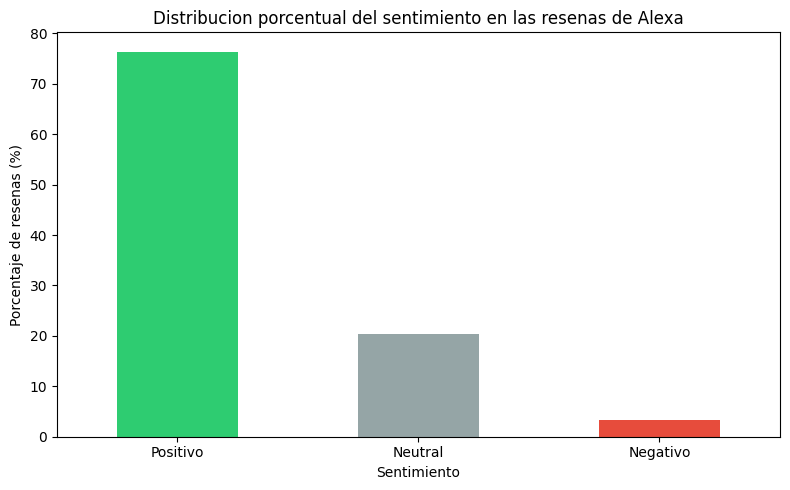

,proportion
sentimiento,
Positivo,76.373452
Neutral,20.323912
Negativo,3.302636


In [8]:
# Calcula la distribucion porcentual de "sentimiento" (value_counts con normalize=True)
# y grafica un bar chart. Agrega titulo, xlabel, ylabel.

df["sentimiento"] = df["comentario"].apply(clasificar_sentimiento)

distribucion = df["sentimiento"].value_counts(normalize=True).reindex(
    ["Positivo", "Neutral", "Negativo"]
) * 100

plt.figure(figsize=(8, 5))
distribucion.plot(kind="bar", color=["#2ecc71", "#95a5a6", "#e74c3c"])
plt.title("Distribucion porcentual del sentimiento en las resenas de Alexa")
plt.xlabel("Sentimiento")
plt.ylabel("Porcentaje de resenas (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

distribucion


## Fase 2: Similitud y Modelado de Topicos

### Embeddings: buscando la reseña ideal

Definí, en una sola oracion en ingles, como se veria una reseña ideal para un producto Alexa. Despues calcula la similitud semantica entre esa reseña ideal y cada una de las reseñas del dataset, usando los vectores de spaCy, e identifica las 5 reseñas mas parecidas.

In [9]:
comentario_ideal = nlp(
    "This is an amazing device, the sound quality is excellent, it connects "
    "easily and works perfectly, super easy to use and a great value for the price."
)  # Escribi aca tu descripcion de una resena ideal


In [10]:
# Recorre los comentarios (podes usar nlp.pipe) y calcula la similitud de cada
# uno contra comentario_ideal. Guarda los resultados en una nueva columna.

similitudes = []
for doc in nlp.pipe(df["comentario"], batch_size=50):
    similitudes.append(doc.similarity(comentario_ideal))

df["similitud_con_ideal"] = similitudes


/tmp/ipykernel_849/1723518382.py:6: UserWarning: [W008] Evaluating Doc.similarity based on empty vectors.
  similitudes.append(doc.similarity(comentario_ideal))


In [11]:
# Ordena el dataset por similitud_con_ideal de forma descendente y muestra
# las 5 resenas mas parecidas (columnas comentario, similitud_con_ideal, sentimiento).

top5_similares = df.sort_values("similitud_con_ideal", ascending=False).head(5)
top5_similares[["comentario", "similitud_con_ideal", "sentimiento"]]


,comentario,similitud_con_ideal,sentimiento
1216,"Such a fun, easy, and convenient device to hav...",0.960678,Positivo
1315,This is the best Alexa enabled device you can ...,0.959551,Positivo
1784,"It's a great product with many good aspects, i...",0.958533,Positivo
416,"It's an echo, and it works. For the price it'...",0.956476,Positivo
989,Easy to use and has great sound...It was a gre...,0.956452,Positivo


### Paso 4: LDA sobre las reseñas negativas

Quedate solo con las reseñas que vos mismo clasificaste como Negativo, y usa Gensim para encontrar 3 topicos entre las quejas. Para esto usa la columna `comentario_limpio` que armaste en el Paso 1.

In [12]:
negativos = df[df["sentimiento"] == "Negativo"].copy()
print("Cantidad de reseñas negativas:", len(negativos))

Cantidad de reseñas negativas: 104


In [13]:
# 1. Converti la columna comentario_limpio de "negativos" en una lista de listas
#    de palabras (separando cada string por espacios).
# 2. Crea el Dictionary de Gensim y filtra las palabras muy raras o muy comunes
#    con filter_extremes (podes usar no_below=5, no_above=0.5 como en clase).
# 3. Crea el corpus (bolsa de palabras) con dictionary.doc2bow.

textos_negativos = [texto.split() for texto in negativos["comentario_limpio"]]

diccionario = corpora.Dictionary(textos_negativos)
diccionario.filter_extremes(no_below=5, no_above=0.5)

corpus = [diccionario.doc2bow(texto) for texto in textos_negativos]


In [14]:
# Entrena un modelo LdaModel con num_topics=3 y passes=10, y muestra las
# palabras clave de cada topico con print_topics().

lda_model = models.LdaModel(
    corpus=corpus,
    id2word=diccionario,
    num_topics=3,
    passes=10,
    random_state=42,
)

for topico in lda_model.print_topics():
    print(topico)


(0, '0.122*"music" + 0.079*"alexa" + 0.074*"use" + 0.069*"sound" + 0.062*"small" + 0.055*"prime" + 0.047*"think" + 0.046*"useless" + 0.039*"play" + 0.039*"speaker"')
(1, '0.103*"work" + 0.081*"amazon" + 0.079*"like" + 0.054*"alexa" + 0.054*"buy" + 0.053*"day" + 0.052*"device" + 0.050*"screen" + 0.041*"come" + 0.041*"play"')
(2, '0.123*"echo" + 0.077*"dot" + 0.073*"set" + 0.067*"work" + 0.060*"time" + 0.049*"device" + 0.042*"tell" + 0.041*"buy" + 0.037*"unit" + 0.034*"turn"')


Mirando las palabras clave, ponele un nombre analitico a cada topico (por ejemplo: "Calidad de sonido", "Conectividad", "Precio"). Escribi tus nombres aca:

- Topico 0 (music, alexa, sound, small, prime, useless, speaker, play): **Calidad de sonido y experiencia como altavoz**. Agrupa quejas sobre el audio, el tamano del dispositivo y su uso para reproducir musica; la palabra "useless" aparece con peso alto, lo que indica frustracion cuando el sonido no cumple expectativas.
- Topico 1 (work, amazon, like, buy, day, device, screen, come, play): **Funcionamiento general y expectativas de compra**. Junta comentarios sobre el dispositivo que no funciona como se esperaba desde el primer dia, problemas de pantalla (relevante para modelos con Show) y decepcion frente a lo prometido por Amazon.
- Topico 2 (echo, dot, set, work, time, tell, buy, unit, turn): **Configuracion y conectividad del Echo Dot**. Reune quejas del proceso de instalacion/emparejamiento ("set", "turn"), la dificultad de que el asistente entienda comandos ("tell") y el tiempo que toma dejarlo funcionando.


## Nubes de palabras por topico

Ya viste cada topico como una lista de palabras con su peso. Ahora armemos una version mas visual: una nube de palabras por topico, donde las palabras con mayor peso aparecen mas grandes. Te puede servir tambien para revisar los nombres que le pusiste a cada topico mas arriba.

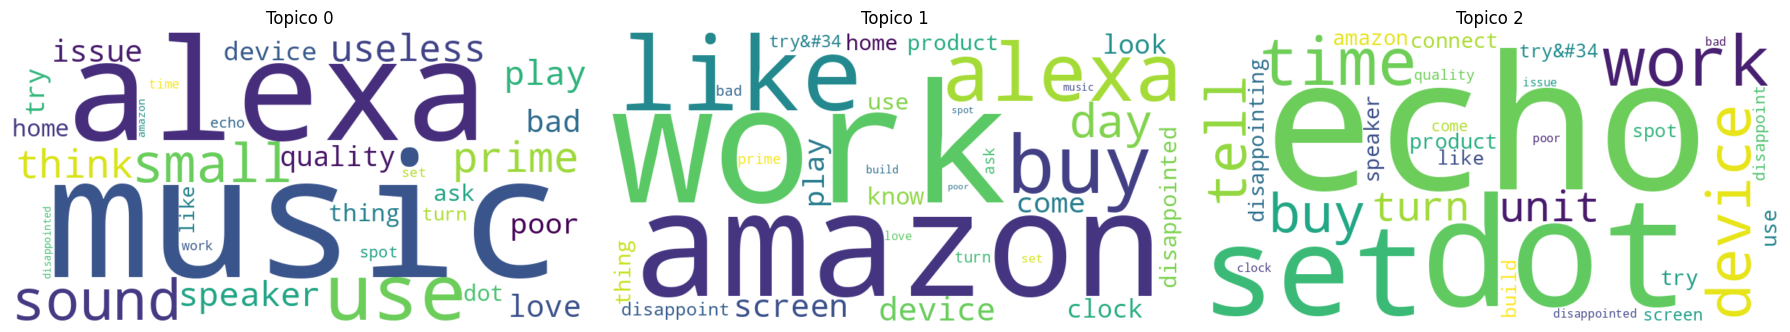

In [15]:
# Para cada uno de los 3 topicos (topico_id de 0 a 2):
# 1. Obtene sus 30 palabras mas representativas con lda_model.show_topic(topico_id, topn=30)
#    y convertilas en un diccionario {palabra: peso} (fijate que show_topic ya te devuelve
#    una lista de tuplas (palabra, peso), lista para pasarle a dict()).
# 2. Genera una nube de palabras con WordCloud(...).generate_from_frequencies(...).
# 3. Mostrala en el subplot correspondiente (ejes[topico_id]), con el titulo "Topico {topico_id}"
#    y sin ejes (axis("off")).

fig, ejes = plt.subplots(1, 3, figsize=(18, 6))

for topico_id in range(3):
    palabras = dict(lda_model.show_topic(topico_id, topn=30))
    nube = WordCloud(width=800, height=400, background_color="white").generate_from_frequencies(palabras)
    ejes[topico_id].imshow(nube, interpolation="bilinear")
    ejes[topico_id].set_title(f"Topico {topico_id}")
    ejes[topico_id].axis("off")

plt.tight_layout()
plt.show()


## Conclusiones

En general, la salud del feedback es muy buena: el 76.4% de las resenas se clasifico como Positivo, un 20.3% como Neutral y solo un 3.3% como Negativo, lo que indica que la gran mayoria de los clientes esta conforme con la linea de productos Alexa. Las 5 resenas mas parecidas al comentario ideal (definido en torno a facilidad de uso, buen sonido, conexion sencilla y buena relacion precio-valor) fueron efectivamente todas Positivas segun TextBlob, lo cual tiene sentido: describen dispositivos que "simplemente funcionan", con buen audio y facilidad de uso, exactamente los atributos que se buscaban. Dentro de las 104 resenas negativas, el LDA encontro tres temas claros: (1) calidad de sonido y experiencia como altavoz, con quejas de que el audio o el dispositivo resultan "useless" para lo que el cliente esperaba; (2) funcionamiento general y expectativas de compra, ligado a dispositivos que fallan desde el primer dia o no cumplen lo prometido; y (3) configuracion y conectividad del Echo Dot, sobre lo dificil que resulta dejarlo instalado y que entienda los comandos de voz. Con estos resultados, Amazon deberia enfocar sus esfuerzos de mejora en simplificar el proceso de configuracion inicial (guias mas claras, mejor deteccion de errores de emparejamiento) y en el control de calidad de audio/hardware antes del envio, ya que son los dos frentes que mas quejas concentran, mientras que el sentimiento general confirma que la propuesta de valor central del producto (facilidad de uso y utilidad diaria) esta funcionando bien.
